# E91: How big is each Qwen update at the template fine-tune's size, and what has it learned there?

**The answer.** The table exists, and the matched step cannot carry the comparison alone. Every arm has a named state nearest the template fine-tune's full update. At that size the TOFU update reads like the unchanged model on its facts. Its smallest saved state holding them is about thirty times that norm. So the comparison reads both: the matched step controls size only, and any claim of new content rests on the full update, with its size stated. The user chose this as a weak endorsement, not having fully followed the question.


## What we were trying to test

The Qwen comparison needs its updates read at a common size, because the TOFU update ends 37 times larger than the template one. The amended plan made the size-matched step the reading the comparison leans on. This job finds that step for each arm, asks whether the TOFU update has learned anything by then, and then asks how large it is once it has.

**The reference** is anchor 1's full update at step 100. Anchor 1 is the template fine-tune, which teaches an answer format the model already follows under a prompt. It reads the two sizes below at 0.4865 and 0.0959.

**Two sizes, read on each saved state.** The unchanged model reads 0 on both.

- **Norm:** the Frobenius norm of the update over the decomposed matrices.
- **KL to start:** $\mathrm{KL}(W_0 \,\|\, W_0 + \delta W)$ per position on the first 16 maths rows, the rows anchor 1's training tracked.

"Nearest" is the smallest absolute log ratio to the reference. An arm that never reaches the reference gets its largest state, flagged.

**The arms.**

- **Anchor 1, two seeds.** The second seed shows how far a repeat lands from the reference.
- **Anchor 2, two seeds.** The fine-tune on TOFU facts about invented authors, the example of content the model lacks.
- **RL and its shuffled-reward null, two seeds each.** The null shows what the same loop moves without a meaningful reward.
- **Own-samples SFT, one seed.** The same prompts and rate as RL, with the model's own correct samples as targets.
- **u1 and u2.** Fine-tunes on GSM8K's human solutions, u1 with no warm-up and u2 with a short one.

**The second stage.** Anchor 2 had no saved state near the reference, so both seeds were retrained and saved at steps 27 to 30. We then read its fact answers there.

**New-word recall** is the share of the reference answer's words, absent from the question, that return in the model's answer. 0 means none and 1 means all. **The filed learning line** is 0.585, halfway from the unchanged model to the full update.

**The third stage, Amendment 1.** The matched states hold no facts. So the user asked for anchor 2 saved where it does, at its smallest saved state past the learning line, at both seeds. Each seed was retrained on one L40 with the same recipe. From step 500, every 50 steps, the trained-wording answers were read, and the first state at or over the line was saved. Seed 42's read at step 500 doubles as a control, because the first TOFU run read the same step on an H100.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_size_grid")
RES = ROOT / "results"
load = lambda path: json.loads(path.read_text())
grid, matched = load(RES / "size_grid.json"), load(RES / "matched.json")
filed = load(RES / "predictions_matched.json")
read = load(ROOT.parent / "qwen_tofu_forms" / "results" / "read.json")
past = load(RES / "past_line.json")


def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in row) + " |" for row in rows]
    display(Markdown("\n".join(out)))


assert matched["done"] and all(s["label"] == "not learned" for s in matched["states"])
assert past["done"] and all(s["past"] for s in past["seeds"].values())
assert not any(grid["arms"][a]["at_norm"]["reached"] for a in ("R_s0", "R_s70", "N_s0", "N_s70", "F_s0"))
assert read["states"]["500"]["trained"]["recall"] < filed["learned_line"] < read["states"]["1000"]["trained"]["recall"]


## What we expected

- **The GSM8K arms:** nearest in norm at step 100, not reaching it.
- **KL, as leans with no record behind them:** RL, the null and own-samples SFT stay under the reference through step 100. u1 and u2 reach it before step 10. Anchor 2 crosses it between steps 50 and 500.
- **Anchor 2's retrain:** nearest near step 30 in norm, and between steps 25 and 45 in KL.
- **Learning:** not learned at any matched state, with trained-wording recall under 0.30. These steps sit inside a 250-step warm-up.
- **The first state past the line:** step 550 or 600 at both seeds, because seed 42 sat 0.015 under the line at step 500 and was rising. The seeds' steps within 100 of each other. That puts its norm at 31 to 34 times anchor 1's. Rephrased recall over 0.40 and under the full update's 0.53.
- **The card control:** the L40 rerun of seed 42's step 500 within 0.03 of the H100's 0.570.

## What we observed

### Does the table exist, and which arms reach the reference?


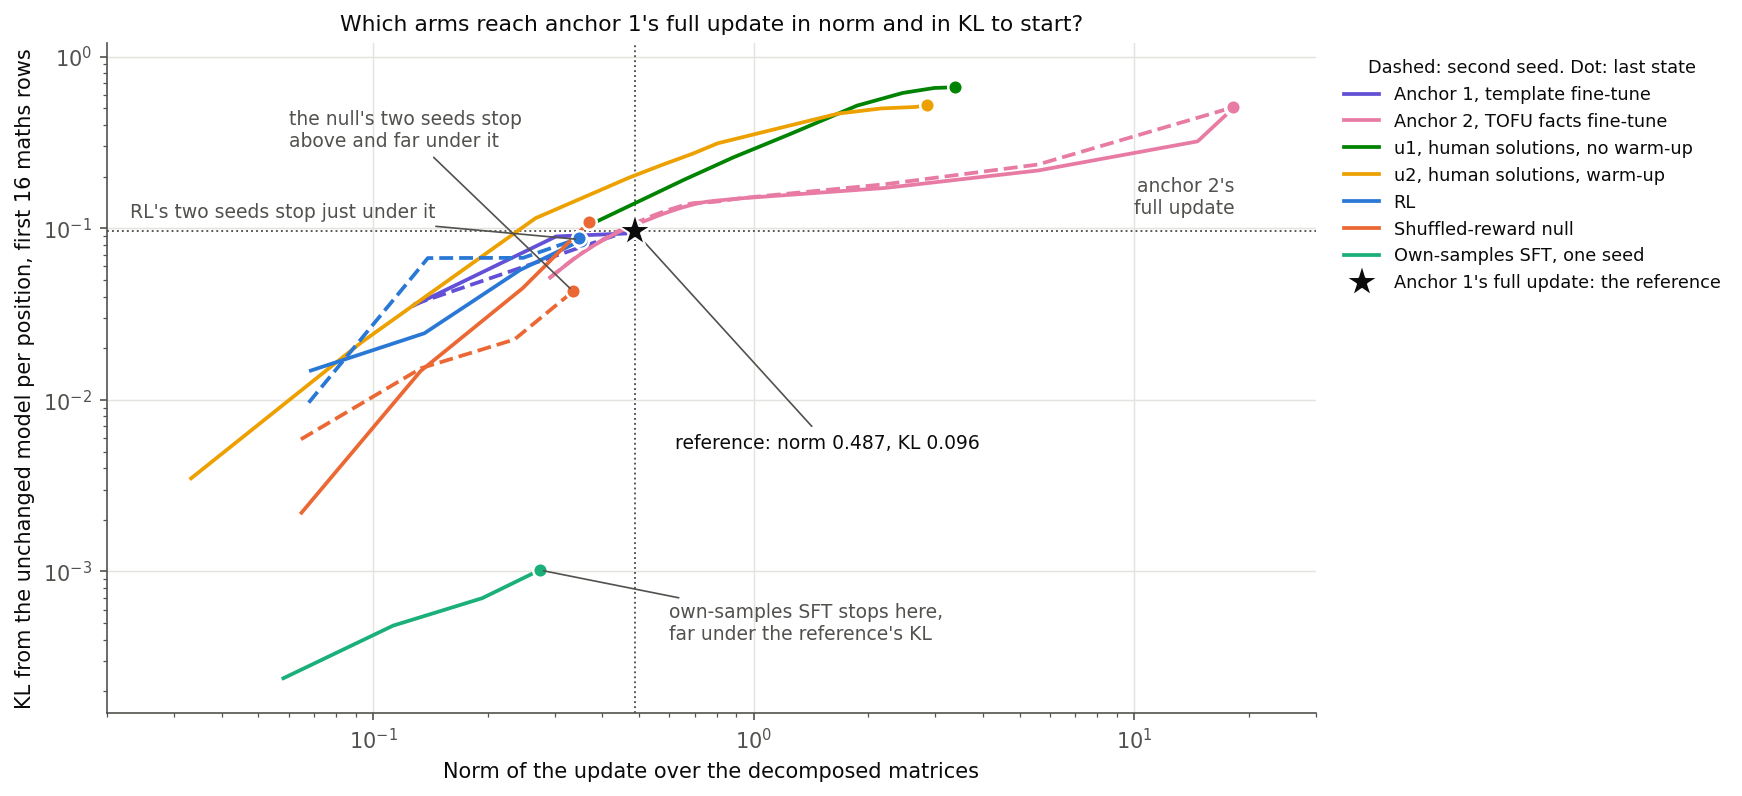

| arm | nearest norm: step | ratio to reference | nearest KL: step | ratio to reference |
|---|---|---|---|---|
| anchor 1, first seed | 100 | 1.00 | 100 | 1 |
| anchor 1, second seed | 100 | 1.00 | 100 | 1.04 |
| anchor 2, seed 42 | 29 | 0.98 | 27 | 0.983 |
| anchor 2, seed 142 | 30 | 1.02 | 27 | 0.991 |
| RL, first seed | 100 | 0.72, not reached | 100 | 0.883, not reached |
| null, first seed | 100 | 0.76, not reached | 100 | 1.13 |
| own-samples SFT | 100 | 0.56, not reached | 100 | 0.0106, not reached |
| RL, second seed | 100 | 0.71, not reached | 100 | 0.909, not reached |
| null, second seed | 100 | 0.69, not reached | 100 | 0.447, not reached |
| u1 | 1 | 0.77 | 1 | 1.1 |
| u2 | 7 | 0.97 | 5 | 1.19 |

In [2]:
display(Image(ROOT / "figures" / "norm_vs_kl.png", width=900))
names = {"anchor1_s0": "anchor 1, first seed", "anchor1_s1": "anchor 1, second seed", "anchor2_s0": "anchor 2, seed 42", "anchor2_s142": "anchor 2, seed 142",
         "R_s0": "RL, first seed", "R_s70": "RL, second seed", "N_s0": "null, first seed", "N_s70": "null, second seed", "F_s0": "own-samples SFT", "u1": "u1", "u2": "u2"}
table(["arm", "nearest norm: step", "ratio to reference", "nearest KL: step", "ratio to reference"],
      [[names[a], r["at_norm"]["step"], f"{r['at_norm']['ratio']:.2f}" + ("" if r["at_norm"]["reached"] else ", not reached"),
        r["at_kl"]["step"], f"{r['at_kl']['ratio']:.3g}" + ("" if r["at_kl"]["reached"] else ", not reached")] for a, r in grid["arms"].items()])


**Reading it.** Yes: every arm has a named state, but only some reach the reference. Anchor 2 passes almost through the star, and u1 and u2 pass above it. All five runs of RL, the null and own-samples SFT stop to its left, because none reaches the norm by step 100. In KL they differ widely. RL ends just under the reference at both seeds. The null's two seeds read 1.13 and 0.45 of it, 2.5 times apart, and one of them reaches it.

Own-samples SFT stops at 0.011 of the reference, at 0.56 of the norm. At step 100, RL's KL is about 80 times SFT's, with SFT's norm about 0.8 of RL's. We do not name a cause. The earlier report on this RL loop, E69, read KL on sampled answers and shows the same order at both seeds.


### Has anchor 2 learned its facts at that size?


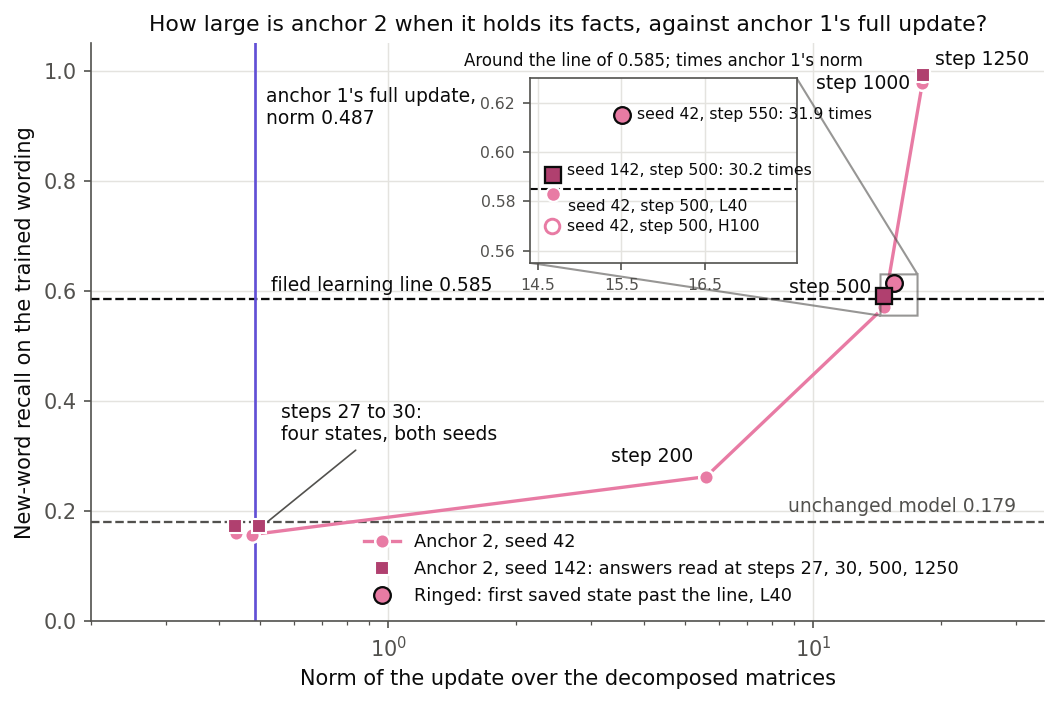

| seed, state | norm | trained-wording recall | filed rule |
|---|---|---|---|
| 42, step 27 | 0.438 | 0.159 | not learned |
| 42, step 29 | 0.477 | 0.157 | not learned |
| 142, step 27 | 0.436 | 0.172 | not learned |
| 142, step 30 | 0.496 | 0.173 | not learned |
| unchanged model | 0 | 0.179 | cannot pass |
| 42, step 200 | 5.597 | 0.262 | not learned |
| 42, step 500 | 14.667 | 0.570 | not learned |
| 42, step 1000 | 18.068 | 0.978 | learned |
| 42, step 1250 | 18.109 | 0.993 | learned |

In [3]:
display(Image(ROOT / "figures" / "recall_vs_norm.png", width=800))
rows = [[f"{s['seed']}, step {s['step']}", f"{s['norm']:.3f}", f"{s['answers']['trained']['recall']:.3f}", s["label"]] for s in matched["states"]]
rows.append(["unchanged model", 0, f"{read['W0']['trained']['recall']:.3f}", "cannot pass"])
rows += [[f"42, step {t}", f"{read['files'][t]['norm']:.3f}", f"{read['states'][t]['trained']['recall']:.3f}",
          "learned" if read["states"][t]["trained"]["recall"] >= filed["learned_line"] else "not learned"] for t in ("200", "500", "1000", "1250")]
table(["seed, state", "norm", "trained-wording recall", "filed rule"], rows)


**Reading it.** No. The filed rule reads "not learned" at all four matched states, both seeds, as expected. Trained-wording recall reads 0.157 to 0.173 against 0.179 unchanged, a little under it, and we do not name a cause. The full update reads 0.99 at both seeds. This wording is the easiest test, so the statement is the strong one. At this size a matched-step reading compares the template fine-tune, finished, with the first steps of a fine-tune.


### How large is the smallest saved state that holds its facts?


In [4]:
ref = past["reference"]
s42, s142 = past["seeds"]["42"], past["seeds"]["142"]
h100 = read["files"]["500"]["norm"], read["states"]["500"]["trained"]["recall"], read["states"]["500"]["para"]["recall"]
states = [("42, step 500, H100", *h100),
          ("42, step 500, L40", s42["checks"][0]["norm"], s42["checks"][0]["trained"], None),
          ("42, step 550, L40, first past the line", s42["norm"], s42["answers"]["trained"]["recall"], s42["answers"]["para"]["recall"]),
          ("142, step 500, L40, first past the line", s142["norm"], s142["answers"]["trained"]["recall"], s142["answers"]["para"]["recall"])]
table(["seed, state, card", "norm", "times anchor 1's norm", "trained-wording recall", "rephrased recall"],
      [[name, f"{norm:.3f}", f"{norm / ref['norm']:.1f}", f"{trained:.3f}", "not read" if para is None else f"{para:.3f}"] for name, norm, trained, para in states])


| seed, state, card | norm | times anchor 1's norm | trained-wording recall | rephrased recall |
|---|---|---|---|---|
| 42, step 500, H100 | 14.667 | 30.1 | 0.570 | 0.425 |
| 42, step 500, L40 | 14.682 | 30.2 | 0.583 | not read |
| 42, step 550, L40, first past the line | 15.510 | 31.9 | 0.615 | 0.434 |
| 142, step 500, L40, first past the line | 14.676 | 30.2 | 0.591 | 0.439 |

**Reading it.** About 30 times anchor 1's norm, at both seeds, in the figure above and its inset. Seed 42's first state past the line is step 550, and seed 142's is step 500. Trained-wording recall there reads 0.615 and 0.591, over the line of 0.585 and far under the full update's 0.99. Rephrased recall reads 0.434 and 0.439, against 0.166 unchanged and about 0.53 at the full update. These states have 31.9 and 30.2 times anchor 1's norm. On the maths rows, which they did not train on, their KL is 3.47 and 3.45 times anchor 1's.

Each size is an upper bound on the crossing's, because the grid reads every 50 steps from step 500. At seed 42 the crossing lies between 30.2 and 31.9 times anchor 1's norm. At seed 142 the first read was already over the line, and its last read under it is step 30, so its crossing is not bracketed from below.

**A caution.** "First past the line" is not sharp between steps 500 and 550. The two cards read seed 42's step 500 at 0.583 and 0.570, which is 0.013 apart. On the L40, that state fell 0.002 under the line and seed 142's fell 0.006 over it. Both margins are smaller than the card difference, so another card could have named a different step.

**What this leaves true about size.** Anchor 1 clears its own filed learning rule at the reference size, by format rate. That rule counts format, not new words, so the two lines are not one scale. Even so, the smallest saved state of anchor 2 holding its facts is about 30 times anchor 1's norm. So the two anchors cannot be compared at equal size while both have done their job. This is what was measured, and we do not name a cause.


## What we learned

Size matching and learning do not line up across the two examples. The state matching anchor 1's size exists and lies on the full update's path, but it reads like the unchanged model on the facts it is meant to teach. Any reading through the decomposition there says what the opening steps of a facts fine-tune do, not what new content looks like. Even the smallest saved state holding the facts is about 30 times anchor 1's norm.

The plan named the matched step as the one the comparison leans on, and the user's answer replaces that: read both, with the matched step a size control only. Any claim that an update adds something new rests on the full update, with its size stated. Anchor 2's first states past the line are saved at both seeds for the rows to read. The user called this a weak endorsement, not having fully followed the question.

## How compelling is the evidence

- **Norm** says nothing of where the update lands.
- **KL** here is on maths rows only. It is off-task for the TOFU arm and says nothing of what it learned on facts.
- **Recall** counts new words only, so a state that has shifted toward fact-like answers without the facts reads near the unchanged model. Batch loss has already fallen from 6.24 to 2.39 by step 30 at seed 42, with recall flat.
- **"Past the line"** uses the easiest wording, so it says the facts are held as trained. The rephrased read says separately how far they carry.
- **Controls.** The zero state read 0 and 0. Anchor 1's step 100 read the earlier run's numbers.
- **Card control.** The L40 rerun of seed 42's step 500 reads 0.583 against the H100's 0.570, inside the filed band of 0.03. It is one state on one pair of cards.
- **Same path.** The retrain against the saved file at step 100 reads 0 at seed 142, on one card type. It reads 0.74% of the norm at seed 42, across two card types. The two seeds sit 90% apart, so the matched states are on the full update's path.
- **Seeds.** Two for each anchor, RL and the null, one for own-samples SFT. Recall along training has seed 42 only, and seed 142 has answers at steps 27, 30, 500 and 1250.
- **Precision.** u1 and u2 exist only as bf16 files, the other arms as fp32.

## Surprises

Two filed leans missed, both leans and not gates. The null at its first seed reached the KL reference, where we leaned it would stay under through step 100. Anchor 2 crossed the KL reference between steps 20 and 50, where we leaned between 50 and 500.

Two filed expected values missed in the third stage, both at seed 142 and both from one event. It was already over the line at step 500, where we expected step 550 or 600. So its size reads 30.2 times anchor 1's norm, where we expected 31 to 34.

One error in the first read: the state list left out u1's step 1 and u2's steps 1, 7, 8 and 9. The lead found this reading the first output, and they were read before the grid was committed. It changed both arms' norm-nearest step.

## What next

1. **Reads through the decomposition at these states** are `qwen-decomp-lead`'s, at the matched step, the first state past the line and the full update. A separation between the anchors at the matched step cannot come from facts the update recalls.
2. **Answers at seed 142 under step 500,** only if a row's reading turns on where exactly that seed crosses the line. Nothing filed does today.

## Departures from the literature

None: no outside source is cited for a definition, recipe or threshold.

## Scorecard

| Filed item | Claim | Read | Verdict |
|---|---|---|---|
| controls | zero state 0, 0; anchor 1 step 100 reads the earlier numbers | as filed | passes |
| `gsm8k_arms_norm` | step 100, not reached | 0.274 to 0.370, none reached | held |
| `kl_leans`, GSM8K | under the reference through step 100 | null, first seed, 1.13 | **lean missed** |
| `kl_leans`, u1 and u2 | reach it before step 10 | step 1, by step 5 | held |
| `kl_leans`, anchor 2 | crosses between steps 50 and 500 | between 20 and 50 | **lean missed** |
| `t_norm`, `t_kl` | about step 30; between 25 and 45 | 29, 30; 27, 27 | held |
| `learned` | not learned, recall under 0.30 | not learned, 0.157 to 0.173 | held |
| rerun control | under a tenth of the seeds' distance | 0.0074 and 0, against 0.899 | on the path |
| Amendment 1 control | L40 rerun within 0.03 of the H100's 0.570 | 0.583, 0.013 apart | passes |
| Amendment 1 `step` | step 550 or 600 at both seeds | 550, 500 | **missed** at seed 142 |
| Amendment 1 `size` | 31 to 34 times anchor 1's norm | 31.9, 30.2 | **missed** at seed 142 |
| Amendment 1 `para` | rephrased recall over 0.40, under 0.53 | 0.434, 0.439 | held |
| Amendment 1 `seeds` | the two seeds' steps within 100 | 50 apart | held |

## Not run

Think-mode answer sets; reads through the decomposition, which are `qwen-decomp-lead`'s; bare and real-fact answers at the matched states and the states past the line; u1's and u2's answers at their matched steps; a second seed of own-samples SFT; answers at seed 142 between steps 30 and 500; answers on the L40 reruns after each seed's first state past the line; rephrased answers on the L40 at seed 42's step 500.

## Provenance

Cluster L40s, `debug` QoS, $0, jobs 52219, 52238 and 52310. Results in `experiments/qwen_size_grid/results/`, figures from its `plot.py`. Full tables and scoring: `reports/analyses/2026-11-05_analysis_e91-size-grid.md`.
